# MSH chain on a 2D substrate: cost scaling of tensor networks, dense and sparse methods

Loads the zero-mode benchmarks of the two notebooks and compares their cost with system size:

| File | Written by | Method |
|---|---|---|
| `tn_zero_modes.csv` | `msh_substrate_tn.ipynb`, section 7 | penalized DMRG on $K = H^2 + \eta^2$, X̂ localization, pairing (MPO/MPS) |
| `py_zero_modes.csv` | `msh_substrate_python.ipynb`, section 5 | dense `eigh` (up to $64\times64$ sites); shift-invert Lanczos with SuperLU (`MMD_AT_PLUS_A`) or MUMPS (METIS) |
| `py_mumps_estimates.csv` | `msh_substrate_python.ipynb`, section 6 | MUMPS analysis: predicted size, flops and memory of the factorization |

All runs are single-threaded. The system is the MSH chain of $\ell = 12$ sites (spins along $\hat z$) centred on a
$2^{L_x}\times2^{L_y}$ substrate; $N$ is the number of sites and $D = 4N$ the BdG dimension. Two scans: the **width scan**
($L_x = 6$, 64 columns, $L_y = 0\dots6$) and the **square scan** ($L_x = L_y = 4\dots11$, up to $2048\times2048$ sites). The point
$L_x = L_y = 6$ belongs to both.

- SuperLU cannot factorize the $1024\times1024$ matrix (it stops with "not enough memory to perform factorization" with only a few GB
  in use); that row is kept with its status and left out of the plots.
- MUMPS was run up to $1024\times1024$. For $2048\times2048$ only its analysis-step estimate is shown (marked as an estimate): the
  run would need about 120 GB. The estimated time scales the measured $1024\times1024$ time by the ratio of the estimated
  factorization flops.
- The tensor network was run up to $2048\times2048$.

**Contents**
1. Time
2. Memory
3. Accuracy
4. Bond dimensions
5. Summary and crossover

In [1]:
import numpy as np
import matplotlib.pyplot as plt

tn = np.genfromtxt("tn_zero_modes.csv", delimiter=",", names=True)
tn = tn[np.argsort(tn["N"])]
py = np.genfromtxt("py_zero_modes.csv", delimiter=",", names=True, dtype=None, encoding=None)
est = np.genfromtxt("py_mumps_estimates.csv", delimiter=",", names=True)
for r in py[py["status"] != "ok"]:
    print(f"failed: {2**r['Lx']}×{2**r['Ly']} {r['method']}: {r['status']}")
ok = py[py["status"] == "ok"]
M = {m: np.sort(ok[ok["method"] == m], order="N") for m in ("superlu", "mumps", "dense")}   # successful runs per method
key = lambda r: (int(r["Lx"]), int(r["Ly"]))

# exact reference: MUMPS where available (up to 1024×1024), else SuperLU
REF = {key(r): r for r in M["superlu"]}
REF.update({key(r): r for r in M["mumps"]})
def ref(a, col):
    return np.array([REF[key(r)][col] if key(r) in REF else np.nan for r in a])

def scan(a, which):
    "Rows of the width scan (Lx = 6) or the square scan (Lx = Ly), sorted by N."
    b = a[(a["Lx"] == 6) if which == "width" else (a["Lx"] == a["Ly"])]
    return b[np.argsort(b["N"])]

def fit(N, t, npts):
    "Power law t = c N^p through the npts largest points (log–log least squares): returns p, c and the fitted range."
    m = np.isfinite(t); N, t = N[m][-npts:], t[m][-npts:]
    p, lc = np.polyfit(np.log(N), np.log(t), 1)
    return p, np.exp(lc), N

# MUMPS at 2048×2048: estimated time = measured 1024×1024 time × (estimated flops ratio)
e = {key(r): r for r in est}
mu = {key(r): r for r in M["mumps"]}
t_mumps_2048 = mu[(10, 10)]["t"] * e[(11, 11)]["est_flops"] / e[(10, 10)]["est_flops"]
print(f"TN: {len(tn)} sizes up to N = {int(tn['N'].max())}; SuperLU: {len(M['superlu'])}, MUMPS: {len(M['mumps'])}, dense: {len(M['dense'])}")
print(f"MUMPS 2048×2048 estimate: {e[(11, 11)]['est_mem_incore_MB'] / 1e3:.0f} GB in core, ~{t_mumps_2048:.0f} s ({t_mumps_2048 / 3600:.1f} h)")

failed: 1024×1024 superlu: MemoryError: SuperLU: not enough memory to perform factorization
TN: 14 sizes up to N = 4194304; SuperLU: 12, MUMPS: 13, dense: 9
MUMPS 2048×2048 estimate: 121 GB in core, ~7983 s (2.2 h)


## 1. Time

Wall time of the zero-mode calculation against $N$. TN: building $H$ and $K$, the three DMRGs and the pairing (`t_total`). Sparse
and dense: the eigensolver, including the factorization. Dashed: power-law fits $t\propto N^p$ through the largest points of the
square scan (TN and MUMPS: four, SuperLU and dense: three), with the exponent in the legend. Open square: the MUMPS estimate at
$2048\times2048$.

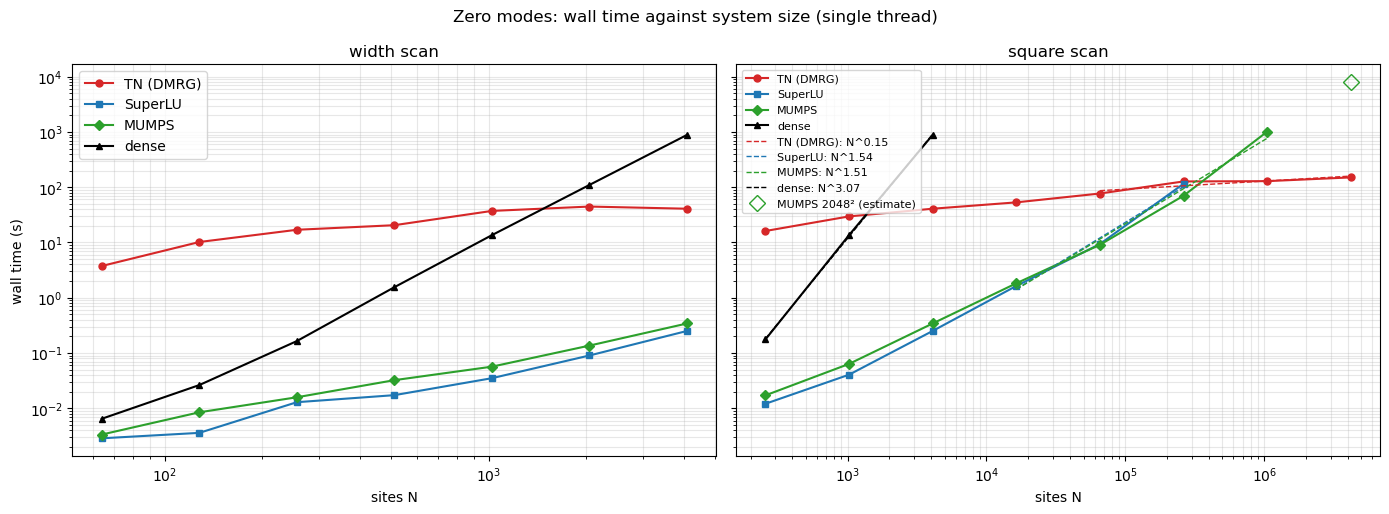

fitted exponents (square scan): TN (DMRG) N^0.15, SuperLU N^1.54, MUMPS N^1.51, dense N^3.07


In [2]:
style = {"TN (DMRG)": ("tab:red", "o"), "SuperLU": ("tab:blue", "s"), "MUMPS": ("tab:green", "D"), "dense": ("k", "^")}
series = lambda which: (("TN (DMRG)", scan(tn, which), "t_total"), ("SuperLU", scan(M["superlu"], which), "t"),
                        ("MUMPS", scan(M["mumps"], which), "t"), ("dense", scan(M["dense"], which), "t"))
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
for j, which in enumerate(("width", "square")):
    for name, a, col in series(which):
        if len(a):
            c, mk = style[name]
            ax[j].loglog(a["N"], a[col], marker=mk, color=c, lw=1.5, ms=5, label=name)
    ax[j].set_xlabel("sites N"); ax[j].set_title(f"{which} scan"); ax[j].grid(True, which="both", alpha=0.3)
exps = {}
for name, a, col in series("square"):
    p, c, Nf = fit(a["N"].astype(float), a[col], 4 if name in ("TN (DMRG)", "MUMPS") else 3)
    exps[name] = p
    Ng = np.geomspace(Nf.min(), Nf.max(), 20)
    ax[1].loglog(Ng, c * Ng**p, "--", color=style[name][0], lw=1, label=f"{name}: N^{p:.2f}")
ax[1].loglog([e[(11, 11)]["N"]], [t_mumps_2048], "D", mfc="none", color="tab:green", ms=8, label="MUMPS 2048² (estimate)")
ax[0].set_ylabel("wall time (s)"); ax[0].legend(); ax[1].legend(fontsize=8, loc="upper left")
fig.suptitle("Zero modes: wall time against system size (single thread)")
fig.tight_layout(); plt.show()
print("fitted exponents (square scan): " + ", ".join(f"{k} N^{v:.2f}" for k, v in exps.items()))

## 2. Memory

Peak resident memory (RSS) of the process doing the calculation. Python: each (size, method) ran in its own forked process, so the
value is that calculation's peak (it includes the kernel's baseline, about 110 MB). Julia: the peak of the whole process up to that
size (sizes ran in increasing $N$), dominated by the Julia runtime and compiled code; the memory of the tensor-network data itself
($K$ and the three MPS) is shown separately. Open squares: the MUMPS analysis estimate of the in-core memory (within 5 % of the
measured peak where both exist). Dashed: $16D^2$ bytes, the dense matrix alone.

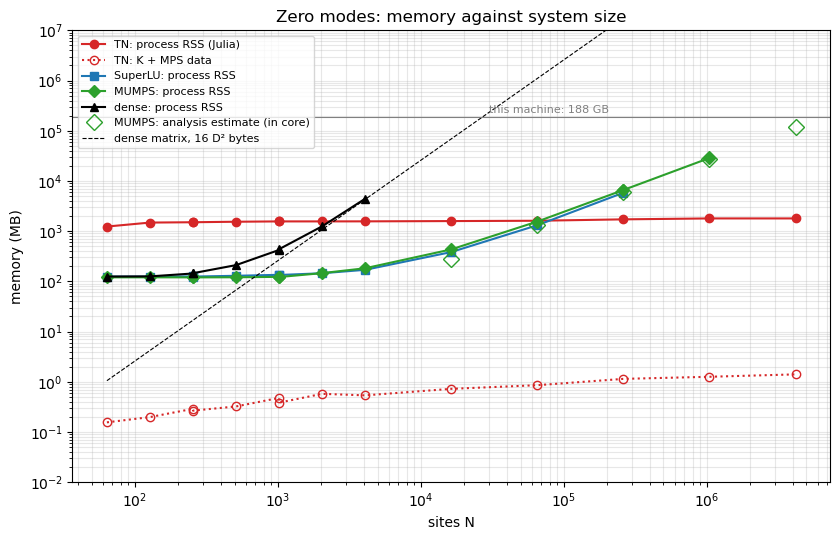

SuperLU RSS grows as N^0.98 over its three largest square-scan sizes
MUMPS RSS grows as N^1.05 over its three largest square-scan sizes
MUMPS 256×256: measured 1552 MB, estimated 1326 MB
MUMPS 512×512: measured 6594 MB, estimated 6117 MB
MUMPS 1024×1024: measured 28636 MB, estimated 27913 MB
TN data (K + MPS) at 2048×2048: 1.40 MB; Julia process RSS 1790 MB


In [3]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.loglog(tn["N"], tn["rss_MB"], "o-", color="tab:red", label="TN: process RSS (Julia)")
ax.loglog(tn["N"], tn["mem_K_MB"] + tn["mem_psi_MB"], "o:", color="tab:red", mfc="none", label="TN: K + MPS data")
for name, m in (("SuperLU", "superlu"), ("MUMPS", "mumps"), ("dense", "dense")):
    a = M[m][np.argsort(M[m]["N"])]
    ax.loglog(a["N"], a["rss_MB"], marker=style[name][1], color=style[name][0], label=f"{name}: process RSS")
ax.loglog(est["N"], est["est_mem_incore_MB"], "D", mfc="none", color="tab:green", ms=8, label="MUMPS: analysis estimate (in core)")
Nd = np.geomspace(tn["N"].min(), tn["N"].max(), 50)
ax.loglog(Nd, 16 * (4 * Nd)**2 / 1e6, "k--", lw=0.8, label="dense matrix, 16 D² bytes")
ax.axhline(188e3, color="gray", lw=0.8); ax.text(3e4, 230e3, "this machine: 188 GB", color="gray", fontsize=8)
ax.set_ylim(1e-2, 1e7)
ax.set_xlabel("sites N"); ax.set_ylabel("memory (MB)"); ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=8)
ax.set_title("Zero modes: memory against system size")
fig.tight_layout(); plt.show()
for name, m in (("SuperLU", "superlu"), ("MUMPS", "mumps")):
    sq = scan(M[m], "square"); p, _, _ = fit(sq["N"].astype(float), sq["rss_MB"], 3)
    print(f"{name} RSS grows as N^{p:.2f} over its three largest square-scan sizes")
for r in M["mumps"]:
    if key(r) in e and r["N"] >= 65536:
        print(f"MUMPS {2**key(r)[0]}×{2**key(r)[1]}: measured {r['rss_MB']:.0f} MB, estimated {e[key(r)]['est_mem_incore_MB']:.0f} MB")
print(f"TN data (K + MPS) at 2048×2048: {tn['mem_K_MB'][-1] + tn['mem_psi_MB'][-1]:.2f} MB; Julia process RSS {tn['rss_MB'][-1]:.0f} MB")

## 3. Accuracy

Differences from the exact result (MUMPS where it ran, otherwise SuperLU; the two and dense agree to round-off):
$|E_f - E_f^{\rm exact}|$ and $|\Delta Q - \Delta Q^{\rm exact}|$. The TN values use `cutoff_K = 1e-20` (`msh_substrate_tn.ipynb`,
section 6). At $2048\times2048$ there is no exact reference; the TN values there are compared with the converged values instead.

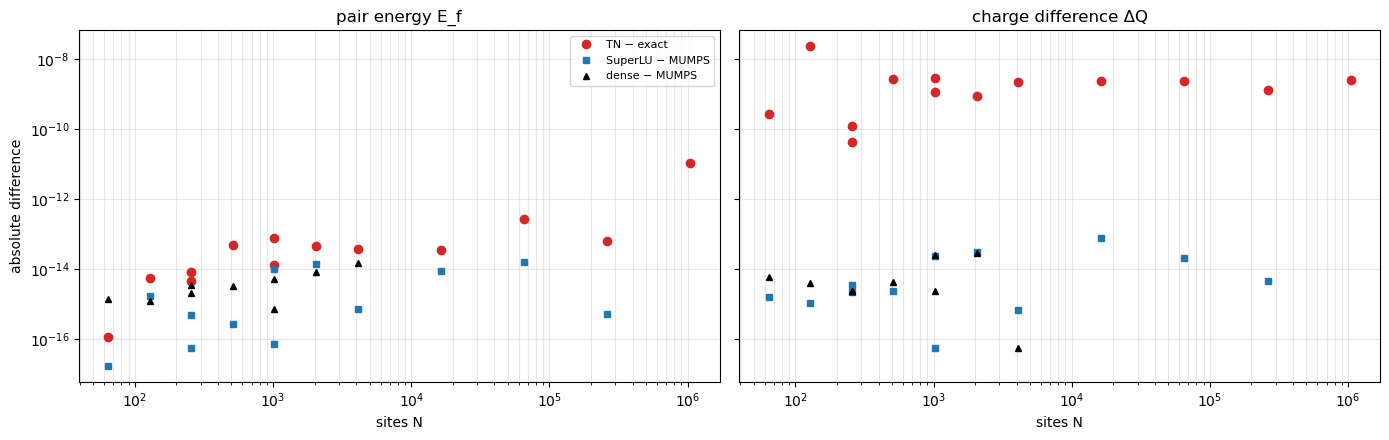

max |ΔQ_TN − exact| = 2.4e-08,  max |E_f,TN − exact| = 1.1e-11  (sizes with an exact reference)
exact at 1024×1024 (MUMPS): E_f = 3.7122847509e-04, ΔQ = -3.4466003632e-03, gap = 0.5529
TN at 2048×2048:            E_f = 3.7122846062e-04, ΔQ = -3.4465999587e-03, gap = 0.5529


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for j, col in enumerate(("E_f", "dQ")):
    ax[j].loglog(tn["N"], np.maximum(np.abs(tn[col] - ref(tn, col)), 1e-17), "o", color="tab:red", label="TN − exact")
    for name, m in (("SuperLU", "superlu"), ("dense", "dense")):
        a = M[m]
        ax[j].loglog(a["N"], np.maximum(np.abs(a[col] - ref(a, col)), 1e-17), style[name][1], color=style[name][0], ms=4,
                     label=f"{name} − MUMPS")
    ax[j].set_xlabel("sites N"); ax[j].grid(True, which="both", alpha=0.3)
    ax[j].set_title({"E_f": "pair energy E_f", "dQ": "charge difference ΔQ"}[col])
ax[0].set_ylabel("absolute difference"); ax[0].legend(fontsize=8)
fig.tight_layout(); plt.show()
print(f"max |ΔQ_TN − exact| = {np.nanmax(np.abs(tn['dQ'] - ref(tn, 'dQ'))):.1e},  "
      f"max |E_f,TN − exact| = {np.nanmax(np.abs(tn['E_f'] - ref(tn, 'E_f'))):.1e}  (sizes with an exact reference)")
big = REF[(10, 10)]
print(f"exact at 1024×1024 (MUMPS): E_f = {big['E_f']:.10e}, ΔQ = {big['dQ']:+.10e}, gap = {big['E_gap']:.4f}")
print(f"TN at 2048×2048:            E_f = {tn['E_f'][-1]:.10e}, ΔQ = {tn['dQ'][-1]:+.10e}, gap = {tn['E_gap'][-1]:.4f}")

## 4. Bond dimensions

$\chi(H)$ of the Hamiltonian MPO, $\chi(K)$ of $K = H^2+\eta^2$ and the largest $\chi(\psi)$ of the DMRG states. If they stay bounded,
the TN cost grows only through the number of qubits, $\log_2 N + 2$.

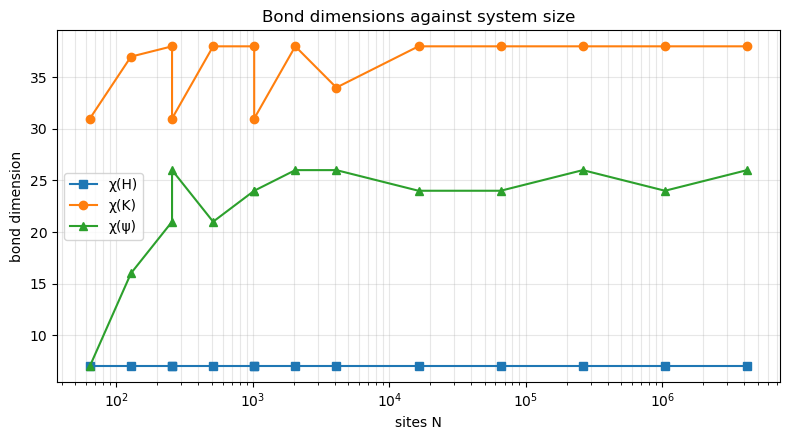

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for col, lab, mk in (("chi_H", "χ(H)", "s"), ("chi_K", "χ(K)", "o"), ("chi_psi", "χ(ψ)", "^")):
    ax.semilogx(tn["N"], tn[col], marker=mk, label=lab)
ax.set_xlabel("sites N"); ax.set_ylabel("bond dimension"); ax.grid(True, which="both", alpha=0.3); ax.legend()
ax.set_title("Bond dimensions against system size")
fig.tight_layout(); plt.show()

## 5. Summary and crossover

Time and peak memory of every method at every size, and the ratio MUMPS/TN of the times (above 1: the tensor network is faster).
`~` marks the MUMPS estimate at $2048\times2048$. The crossover is where the MUMPS and TN times are equal, found by log–log
interpolation between the two square-scan sizes that bracket it.

In [6]:
L_ = {m: {key(r): r for r in py[py["method"] == m]} for m in ("superlu", "mumps", "dense")}
def cell(m, k, col, fmt, w):
    r = L_[m].get(k)
    if r is None:
        return f"{'—':>{w}s}"
    return f"{'failed':>{w}s}" if r["status"] != "ok" else format(r[col], fmt).rjust(w)
print(f"{'substrate':>11s} {'N':>8s} | {'TN':>6s} {'SuperLU':>8s} {'MUMPS':>8s} {'dense':>7s} {'MU/TN':>6s} | "
      f"{'TN':>6s} {'SuperLU':>8s} {'MUMPS':>8s} {'dense':>7s}")
print(f"{'':>11s} {'':>8s} | {'time (s)':^40s} | {'peak memory (MB)':^34s}")
for r in tn:
    k = key(r)
    mu_t = L_["mumps"].get(k)
    if k == (11, 11):
        mt, mm, ratio = f"{'~' + format(t_mumps_2048, '.0f'):>8s}", f"{'~' + format(e[k]['est_mem_incore_MB'], '.0f'):>8s}", \
                        f"{t_mumps_2048 / r['t_total']:6.1f}"
    else:
        mt, mm = cell("mumps", k, "t", ".2f", 8), cell("mumps", k, "rss_MB", ".0f", 8)
        ratio = f"{mu_t['t'] / r['t_total']:6.2f}" if mu_t is not None and mu_t["status"] == "ok" else f"{'—':>6s}"
    print(f"{2**k[0]:>5d}×{2**k[1]:<5d} {int(r['N']):8d} | {r['t_total']:6.1f} {cell('superlu', k, 't', '.2f', 8)} {mt} "
          f"{cell('dense', k, 't', '.1f', 7)} {ratio} | {r['rss_MB']:6.0f} {cell('superlu', k, 'rss_MB', '.0f', 8)} {mm} "
          f"{cell('dense', k, 'rss_MB', '.0f', 7)}")

# crossover N where t_MUMPS = t_TN, square scan
sq_tn = {key(r): r for r in scan(tn, "square")}
pts = sorted((r["N"], np.log(r["t"] / sq_tn[key(r)]["t_total"])) for r in scan(M["mumps"], "square") if key(r) in sq_tn)
for (n1, d1), (n2, d2) in zip(pts, pts[1:]):
    if d1 < 0 <= d2:
        Nc = np.exp(np.log(n1) + (np.log(n2) - np.log(n1)) * (-d1) / (d2 - d1))
        print(f"\ncrossover (MUMPS time = TN time): N ≈ {Nc:.2e} sites (≈ {np.sqrt(Nc):.0f} × {np.sqrt(Nc):.0f}), "
              f"between {int(np.sqrt(n1))}² and {int(np.sqrt(n2))}²")

  substrate        N |     TN  SuperLU    MUMPS   dense  MU/TN |     TN  SuperLU    MUMPS   dense
                     |                 time (s)                 |          peak memory (MB)         
   64×1           64 |    3.8     0.00     0.00     0.0   0.00 |   1233      124      120     125
   64×2          128 |   10.2     0.00     0.01     0.0   0.00 |   1480      124      120     125
   64×4          256 |   17.0     0.01     0.02     0.2   0.00 |   1504      124      120     145
   16×16         256 |   16.1     0.01     0.02     0.2   0.00 |   1504      125      120     143
   64×8          512 |   20.6     0.02     0.03     1.6   0.00 |   1538      129      120     210
   64×16        1024 |   37.3     0.04     0.06    13.6   0.00 |   1562      134      122     436
   32×32        1024 |   29.7     0.04     0.06    13.6   0.00 |   1562      135      123     421
   64×32        2048 |   44.7     0.09     0.14   110.2   0.00 |   1562      145      146    1247
   64×64        4